# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`ransformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:
1. Якщо б тренер BPE отримав один суцільний рядок виникла б проблема з токенізацією. BPE починає рахувати частоти пар слів на місті початку нового вірша. В результаті токенізатор може утворити спільний токен із двох абсолютно не пов'язаних слів з різних текстів.
2.
- Нормалізація - будь-яке очищення тексту, що вважається необхідним, наприклад, видалення пробілів чи діакритичних знаків, нормалізація Unicode тощо.
- Попереднє токенізування - розбиття вхідних даних на слова
- Пропускання вхідних даних через модель - використання попередньо токенізованих слів для отримання послідовності токенів
- Постобробка - додавання спеціальних токенів токенізатора, генерування маски уваги та ідентифікаторів типів токенів
3. \<unk> та \<eos> — це спеціальні токени
   \<unk> - Unknown. Для обробки слів або символів, яких немає у словнику токенізатора.
   \<eos> - End of Sequence. Вказує моделі, що текст закінчився.
4. Зменшення VOCAB_SIZE з 16000 до 4000 зазвичай збільшує середню кількість токенів на вірш, оскільки рідкісні слова розбиваються на менші частини. Частка <unk> при цьому не обов’язково зростає, адже ByteLevel BPE може кодувати навіть рідкісні слова та символи за допомогою байтових токенів.
5. Токен <eos> вставляють між віршами, щоб позначити кінець кожного окремого тексту. Це допомагає mini-GPT розуміти, де закінчується один вірш і починається інший.
Якщо прибрати <eos>, модель сприйматиме сусідні вірші як один суцільний текст і може навчитися продовжувати один вірш іншим без логічного переходу.
6. train_data і val_data — це одновимірні масиви цілих чисел, елементи яких є ID токенів, отриманих після токенізації тексту.
8. causal_mask є нижньотрикутною, тому що кожен токен може враховувати себе та попередні токени, але не майбутні. Верхньотрикутна маска блокувала б доступ до попереднього контексту, порушуючи правильний порядок авторегресивної генерації.
Якщо прибрати маску, під час навчання модель зможе бачити майбутні токени й підглядати правильні відповіді. Але під час генерації ці токени ще невідомі, тому модель працюватиме гірше.
9. Чекпоінти збігаються, якщо найменший val_loss досягнуто на останній ітерації тренування. Якщо val_loss був найменшим раніше, то найкращий чекпоінт відрізняється від останнього.
11. температура визначає, наскільки сильно модель віддає перевагу ймовірнішим токенам. Менша температура сильніше, вища слабше.
12. top_p визначає, які токени взагалі залишаються доступними для вибору. Обирає серед наймешної групи токенів, чия сумарна ймовірність <= р

---
## 1. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [ ]:
import sys
import os
import math
import time
import random

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab4"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab4


In [ ]:

from datasets import load_dataset
import pandas as pd
dataset = load_dataset(
    "wikimedia/wikipedia",
    "20231101.uk",
    split="train"
)

dataset_subset = dataset.select(range(1000))

df = dataset_subset.to_pandas()

texts = df["text"].dropna().tolist()

print("Кількість статей:", len(df))
total_chars = sum(len(text) for text in texts)
print("Довжина корпусу в символах:", total_chars)
print(texts[0][:500])


Кількість статей: 1000
Довжина корпусу в символах: 7759919
Геогра́фія, або заст. земле́пис (від  — опис Землі; де  — Земля і  — писати, описувати) — система наук, що вивчає географічну оболонку Землі (епігеосферу), її просторову природну і соціально-економічну різноманітність, господарство і населення планети, окремих її регіонів та країн, а також зв'язки між природним середовищем і діяльністю людини. В сучасному розумінні поняття «географія» заміщено поняттям «географічні науки».

Поняття 
Уперше термін «географія» був запропонований давньогрецьким гео


In [ ]:

from transformers import AutoTokenizer

base_tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2.5-0.5B-Instruct"
)

new_tokenizer = base_tokenizer.train_new_from_iterator(
    texts,
    vocab_size=500
)

print("Розмір нового словника:", len(new_tokenizer))
print(new_tokenizer.tokenize("Українська мова надзвичайно багата."))


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Розмір нового словника: 508
['Ð', '£', 'ÐºÑĢÐ°ÑĹÐ½', 'ÑģÑĮÐºÐ°', 'ĠÐ¼', 'Ð¾Ð²Ð°', 'ĠÐ½Ð°', 'Ð´', 'Ð·', 'Ð²', 'Ð¸Ñĩ', 'Ð°Ð¹', 'Ð½Ð¾', 'ĠÐ±', 'Ð°', 'Ð³', 'Ð°ÑĤ', 'Ð°', '.']


BPE

In [ ]:

from tokenizers import Tokenizer, models, trainers
from tokenizers import pre_tokenizers, decoders

bpe_tokenizer = Tokenizer(
    models.BPE(unk_token="[UNK]")
)

bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)
bpe_tokenizer.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(
    vocab_size=1000,
    special_tokens=["[UNK]"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet()
)

bpe_tokenizer.train_from_iterator(
    texts,
    trainer=bpe_trainer
)

print("Розмір словника:", bpe_tokenizer.get_vocab_size())
print(
    bpe_tokenizer.encode(
        "Українська мова надзвичайно багата."
    ).tokens
)


Розмір словника: 1000
['Ð£', 'ÐºÑĢÐ°ÑĹÐ½', 'ÑģÑĮÐºÐ°', 'ĠÐ¼', 'Ð¾Ð²Ð°', 'ĠÐ½Ð°Ð´', 'Ð·', 'Ð²', 'Ð¸Ñĩ', 'Ð°Ð¹', 'Ð½Ð¾', 'ĠÐ±', 'Ð°Ð³', 'Ð°ÑĤ', 'Ð°', '.']


wordpiece

In [ ]:

from tokenizers import Tokenizer, models, trainers, pre_tokenizers

wordpiece_tokenizer = Tokenizer(
    models.WordPiece(unk_token="[UNK]")
)

wordpiece_tokenizer.pre_tokenizer = (
    pre_tokenizers.BertPreTokenizer()
)

wordpiece_trainer = trainers.WordPieceTrainer(
    vocab_size=1000,
    special_tokens=[
        "[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"
    ]
)

wordpiece_tokenizer.train_from_iterator(
    texts,
    trainer=wordpiece_trainer
)

print("Розмір словника:", wordpiece_tokenizer.get_vocab_size())
print(
    wordpiece_tokenizer.encode(
        "Українська мова надзвичайно багата."
    ).tokens
)


Розмір словника: 1000
['У', '##країн', '##ська', 'м', '##ов', '##а', 'на', '##д', '##з', '##в', '##ич', '##а', '##й', '##но', 'б', '##а', '##г', '##ат', '##а', '.']


unigram

In [ ]:

from tokenizers import Tokenizer, models, trainers, pre_tokenizers

unigram_tokenizer = Tokenizer(
    models.Unigram()
)

unigram_tokenizer.pre_tokenizer = (
    pre_tokenizers.Metaspace()
)

unigram_trainer = trainers.UnigramTrainer(
    vocab_size=1000,
    special_tokens=["[UNK]"],
    unk_token="[UNK]"
)

unigram_tokenizer.train_from_iterator(
    texts,
    trainer=unigram_trainer
)

print("Розмір словника:", unigram_tokenizer.get_vocab_size())
print(
    unigram_tokenizer.encode(
        "Українська мова надзвичайно багата."
    ).tokens
)


Розмір словника: 1000
['▁Українськ', 'а', '▁мов', 'а', '▁на', 'д', 'з', 'в', 'ич', 'а', 'й', 'но', '▁', 'ба', 'га', 'та', '.']


порівняння

In [ ]:

import pandas as pd

sample = "\n".join(texts[:1000])

test_words = [
    "Україна",
    "людина",
    "навчання",
    "відповідальність",
    "нейромережевий",
    "псевдонауковість",
    "ґрунт",
    "найрізноманітнішими"
]

print("Кількість символів у зразку:", len(sample))
print("Кількість тестових слів:", len(test_words))


Кількість символів у зразку: 7760918
Кількість тестових слів: 8


In [ ]:

tokenizers = {
    "BPE": bpe_tokenizer,
    "WordPiece": wordpiece_tokenizer,
    "Unigram": unigram_tokenizer
}

results = []

for name, tokenizer in tokenizers.items():
    encoded = tokenizer.encode(sample)

    results.append({
        "Алгоритм": name,
        "Розмір словника": tokenizer.get_vocab_size(),
        "Кількість токенів у зразку": len(encoded.ids),
        "Токенів на 1000 символів": round(
            len(encoded.ids) / max(len(sample), 1) * 1000, 2
        )
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)


,Алгоритм,Розмір словника,Кількість токенів у зразку,Токенів на 1000 символів
0,BPE,1000,3698010,476.49
1,WordPiece,1000,4622572,595.62
2,Unigram,1000,3899144,502.41


---
## 2. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

In [ ]:

from tokenizers import Tokenizer, models, trainers
from tokenizers import pre_tokenizers, decoders

VOCAB_SIZE = 4000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

bpe_tokenizer = Tokenizer(
    models.BPE(unk_token="<unk>")
)

bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)
bpe_tokenizer.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS
)

bpe_tokenizer.train_from_iterator(
    texts,
    trainer=bpe_trainer
)

bpe_vocab = bpe_tokenizer.get_vocab()

itos = [None] * len(bpe_vocab)
for tok, idx in bpe_vocab.items():
    itos[idx] = tok

stoi = bpe_vocab
UNK_ID = stoi["<unk>"]
EOS_ID = stoi["<eos>"]

def tokenize(text: str) -> list[str]:
    return bpe_tokenizer.encode(text).tokens

def encode(tokens: list[str]) -> list[int]:
    return [stoi.get(t, UNK_ID) for t in tokens]

def decode(ids: list[int]) -> str:
    return bpe_tokenizer.decode(ids)

print("Розмір словника BPE:", len(itos))
print("ID <unk>:", UNK_ID)
print("ID <eos>:", EOS_ID)
print("Тест:", tokenize("Українська мова надзвичайно багата."))


Розмір словника BPE: 4000
ID <unk>: 0
ID <eos>: 1
Тест: ['Ð£ÐºÑĢÐ°ÑĹÐ½', 'ÑģÑĮÐºÐ°', 'ĠÐ¼Ð¾Ð²Ð°', 'ĠÐ½Ð°Ð´', 'Ð·Ð²Ð¸ÑĩÐ°Ð¹', 'Ð½Ð¾', 'ĠÐ±Ð°Ð³Ð°ÑĤ', 'Ð°', '.']


In [ ]:

import gc
import numpy as np
import torch

ENCODE_BATCH_SIZE = 1000

token_id_chunks = []

for start in range(0, len(texts), ENCODE_BATCH_SIZE):
    batch = texts[start:start + ENCODE_BATCH_SIZE]

    encodings = bpe_tokenizer.encode_batch(batch)

    for enc in encodings:
        ids = np.array(
            enc.ids + [EOS_ID],
            dtype=np.int32
        )
        token_id_chunks.append(ids)

    del encodings

    if start % 10_000 == 0:
        print(
            f"Оброблено {min(start + ENCODE_BATCH_SIZE, len(texts))}"
            f" / {len(texts)} документів"
        )

token_ids = np.concatenate(token_id_chunks)

del token_id_chunks
gc.collect()

unk_share = (token_ids == UNK_ID).mean()

print("Кількість токенів:", len(token_ids))
print(f"Частка <unk>: {unk_share:.4%}")
print("Тип масиву:", token_ids.dtype)

data = torch.from_numpy(token_ids.astype(np.int64))

del token_ids
gc.collect()

print("Форма закодованого корпусу:", data.shape)
print("Тип тензора:", data.dtype)


Оброблено 1000 / 1000 документів
Кількість токенів: 2582212
Частка <unk>: 0.0000%
Тип масиву: int32
Форма закодованого корпусу: torch.Size([2582212])
Тип тензора: torch.int64


In [ ]:

split_idx = int(len(data) * 0.9)

train_data = data[:split_idx]
val_data = data[split_idx:]

print("train:", train_data.shape)
print("val:", val_data.shape)

print(
    "Частка train:",
    round(len(train_data) / len(data) * 100, 2),
    "%"
)
print(
    "Частка val:",
    round(len(val_data) / len(data) * 100, 2),
    "%"
)


train: torch.Size([2323990])
val: torch.Size([258222])
Частка train: 90.0 %
Частка val: 10.0 %


### 3.1. Гіперпараметри

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Використовуємо: cuda
GPU: Tesla T4


In [ ]:
CONTEXT_LEN = 64        # скільки попередніх токенів бачить модель
EMBED_DIM = 128         # розмірність embedding
N_HEADS = 4             # кількість attention-голів
N_LAYERS = 4            # кількість блоків трансформера
DROPOUT = 0.1           # рівень dropout для регуляризації
BATCH_SIZE = 64         # розмір батчу
LEARNING_RATE = 3e-4    # швидкість навчання
MAX_ITERS = 8000        # кількість ітерацій навчання
EVAL_INTERVAL = 250     # інтервал (в ітераціях) для оцінки моделі на валідаційній вибірці
EVAL_ITERS = 50         # кількість ітерацій для оцінки на валідаційній вибірці

assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS


In [ ]:
def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Форма батчу x:", xb.shape, " y:", yb.shape)
assert torch.all(xb[:, 1:] == yb[:, :-1]), "Помилка"

Форма батчу x: torch.Size([64, 64])  y: torch.Size([64, 64])


In [ ]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        # Причинна маска: нижньотрикутна матриця одиниць. register_buffer,
        # а не звичайний атрибут — щоб .to(device) переносив її разом з моделлю.
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)   # (B, T, head_dim)
        k = self.key(x)     # (B, T, head_dim)
        v = self.value(x)   # (B, T, head_dim)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])   # (B, T, T)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v   # (B, T, head_dim)


In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


In [ ]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


In [ ]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)                                   # (B, T, C)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)   # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature   # лише останню позицію

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


In [ ]:
model = MiniGPT(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Кількість параметрів: {n_params:,}")


Кількість параметрів: 1,828,000


In [ ]:
from torch.utils.tensorboard import SummaryWriter

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "mini_gpt_v1"))

FIRST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_v2_first.pt")
BEST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_v2_best.pt")

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)
        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60
        print(f"iter {it:5d}  train_loss={losses['train']:.3f}  "
              f"val_loss={losses['val']:.3f}  ({elapsed_min:.1f} хв)")

        # На диск пишемо лише 2 файли, не по чекпоінту на кожен EVAL_INTERVAL:
        # "перший" — бейзлайн майже випадкової ініціалізації (для порівняння в 3.10),
        # і "найкращий" — перезаписується щоразу, як з'являється новий мінімум val_loss.
        if it == 0:
            torch.save(model.state_dict(), FIRST_CKPT_PATH)

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it
            torch.save(model.state_dict(), BEST_CKPT_PATH)

writer.close()
print(f"\nТренування завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкращий чекпоінт: iter {best_iter}  (val_loss={best_val_loss:.3f})")

iter     0  train_loss=8.412  val_loss=8.398  (0.0 хв)
iter   250  train_loss=6.681  val_loss=6.523  (0.2 хв)
iter   500  train_loss=6.102  val_loss=5.956  (0.3 хв)
iter   750  train_loss=5.611  val_loss=5.488  (0.5 хв)
iter  1000  train_loss=5.244  val_loss=5.209  (0.7 хв)
iter  1250  train_loss=5.000  val_loss=4.997  (0.8 хв)
iter  1500  train_loss=4.830  val_loss=4.836  (1.0 хв)
iter  1750  train_loss=4.695  val_loss=4.684  (1.2 хв)
iter  2000  train_loss=4.588  val_loss=4.606  (1.3 хв)
iter  2250  train_loss=4.519  val_loss=4.552  (1.5 хв)
iter  2500  train_loss=4.389  val_loss=4.486  (1.6 хв)
iter  2750  train_loss=4.380  val_loss=4.429  (1.8 хв)
iter  3000  train_loss=4.288  val_loss=4.389  (1.9 хв)
iter  3250  train_loss=4.263  val_loss=4.346  (2.1 хв)
iter  3500  train_loss=4.218  val_loss=4.320  (2.3 хв)
iter  3750  train_loss=4.147  val_loss=4.257  (2.4 хв)
iter  4000  train_loss=4.157  val_loss=4.232  (2.6 хв)
iter  4250  train_loss=4.094  val_loss=4.196  (2.8 хв)
iter  4500

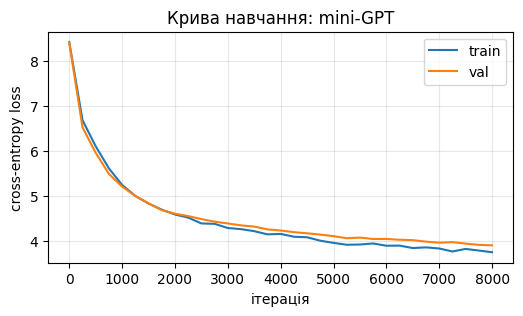

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(checkpoint_iters, train_losses, label="train")
plt.plot(checkpoint_iters, val_losses, label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


In [ ]:
def generate_text(state_dict_path: str, prompt: str, max_new_tokens: int = 40,
                   temperature: float = 0.8, top_k: int = 40) -> str:
    model.load_state_dict(torch.load(state_dict_path, map_location=device))
    prompt_ids = torch.tensor([encode(tokenize(prompt))], dtype=torch.long).to(device)
    out_ids = model.generate(prompt_ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out_ids[0].tolist())


PROMPT = "Реве та стогне"

print("=== Ранній чекпоінт (iter", checkpoint_iters[0], ") ===")
print(generate_text(FIRST_CKPT_PATH, PROMPT))
print(f"\n=== Найкращий чекпоінт (iter {best_iter}, val_loss={best_val_loss:.3f}) ===")
print(generate_text(BEST_CKPT_PATH, PROMPT))

=== Ранній чекпоінт (iter 0 ) ===
Реве та стогне Федса роціуляррах математик ISBN побудкував б лише партії Володатьехант техед верес трирейспанA колиш званa станучОсманлітейн істор України етнгельZ Запорозтвораніяеннін

=== Найкращий чекпоінт (iter 7999, val_loss=3.903) ===
Реве та стогне, його честь якого створили до складу. У Багасим у Поті стався в Україні.

В Україні 
 У березні 2013 році у світі  
 Під час російсько


### 3.1. Гіперпараметри (варіант 2)

In [ ]:
CONTEXT_LEN = 128
EMBED_DIM = 256
N_HEADS = 8
N_LAYERS = 6
DROPOUT = 0.15
BATCH_SIZE = 64
LEARNING_RATE = 2e-4
MAX_ITERS = 10000
EVAL_INTERVAL = 500
EVAL_ITERS = 50

assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS


In [ ]:
def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Форма батчу x:", xb.shape, " y:", yb.shape)
assert torch.all(xb[:, 1:] == yb[:, :-1]), "Помилка"

Форма батчу x: torch.Size([64, 128])  y: torch.Size([64, 128])


In [ ]:
model = MiniGPT(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Кількість параметрів: {n_params:,}")


Кількість параметрів: 6,819,232


In [ ]:
from torch.utils.tensorboard import SummaryWriter

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "mini_gpt_v2"))

FIRST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_v2_first.pt")
BEST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_v2_best.pt")

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)
        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60
        print(f"iter {it:5d}  train_loss={losses['train']:.3f}  "
              f"val_loss={losses['val']:.3f}  ({elapsed_min:.1f} хв)")

        # На диск пишемо лише 2 файли, не по чекпоінту на кожен EVAL_INTERVAL:
        # "перший" — бейзлайн майже випадкової ініціалізації (для порівняння в 3.10),
        # і "найкращий" — перезаписується щоразу, як з'являється новий мінімум val_loss.
        if it == 0:
            torch.save(model.state_dict(), FIRST_CKPT_PATH)

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it
            torch.save(model.state_dict(), BEST_CKPT_PATH)

writer.close()
print(f"\nТренування завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкращий чекпоінт: iter {best_iter}  (val_loss={best_val_loss:.3f})")

iter     0  train_loss=8.308  val_loss=8.284  (0.1 хв)
iter   500  train_loss=5.338  val_loss=5.286  (1.6 хв)
iter  1000  train_loss=4.605  val_loss=4.617  (3.0 хв)
iter  1500  train_loss=4.249  val_loss=4.320  (4.5 хв)
iter  2000  train_loss=4.056  val_loss=4.171  (6.0 хв)
iter  2500  train_loss=3.895  val_loss=4.045  (7.4 хв)
iter  3000  train_loss=3.740  val_loss=3.946  (8.9 хв)
iter  3500  train_loss=3.651  val_loss=3.834  (10.4 хв)
iter  4000  train_loss=3.561  val_loss=3.770  (11.9 хв)
iter  4500  train_loss=3.462  val_loss=3.727  (13.3 хв)
iter  5000  train_loss=3.374  val_loss=3.627  (14.8 хв)
iter  5500  train_loss=3.330  val_loss=3.599  (16.3 хв)
iter  6000  train_loss=3.287  val_loss=3.549  (17.7 хв)
iter  6500  train_loss=3.212  val_loss=3.523  (19.2 хв)
iter  7000  train_loss=3.125  val_loss=3.506  (20.7 хв)
iter  7500  train_loss=3.093  val_loss=3.489  (22.1 хв)
iter  8000  train_loss=3.029  val_loss=3.455  (23.6 хв)
iter  8500  train_loss=2.973  val_loss=3.417  (25.1 хв)

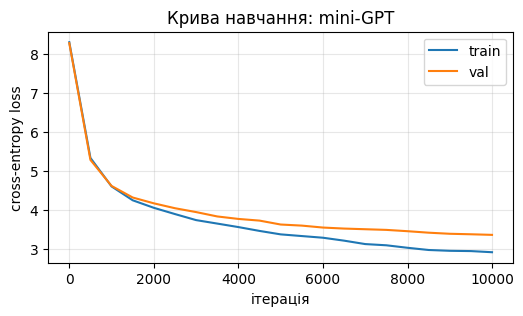

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(checkpoint_iters, train_losses, label="train")
plt.plot(checkpoint_iters, val_losses, label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


In [ ]:
def generate_text(state_dict_path: str, prompt: str, max_new_tokens: int = 40,
                   temperature: float = 0.8, top_k: int = 40) -> str:
    model.load_state_dict(torch.load(state_dict_path, map_location=device))
    prompt_ids = torch.tensor([encode(tokenize(prompt))], dtype=torch.long).to(device)
    out_ids = model.generate(prompt_ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out_ids[0].tolist())


PROMPT = "Реве та стогне"

print("=== Ранній чекпоінт (iter", checkpoint_iters[0], ") ===")
print(generate_text(FIRST_CKPT_PATH, PROMPT))
print(f"\n=== Найкращий чекпоінт (iter {best_iter}, val_loss={best_val_loss:.3f}) ===")
print(generate_text(BEST_CKPT_PATH, PROMPT))

=== Ранній чекпоінт (iter 0 ) ===
Реве та стогне морідерланд бат шт революція першепохцькі історії полі Гздerомет роз смероманіт мистецт верес зах Фердин дуже Союз Руд люд 1992олітична філюнолот математ пог медицини напис вик ст володар країнае метою

=== Найкращий чекпоінт (iter 9999, val_loss=3.361) ===
Реве та стогне значення має можливість.

Вища освіта об'єкта 

Міжність певна функціонує слово для всіх мовних мов програмування, що вивчає розглядати


---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

### 4.0. Запустіть приклади виконання різних NLP задач

In [ ]:
!pip install transformers[sentencepiece]

In [ ]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [ ]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [ ]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

... (14 outputs left out)

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'generated_text': 'In this course, we will teach you how to create a custom web interface to create a web interface to the Java EE EE EE EE EE EE EE'}, {'generated_text': 'In this course, we will teach you how to build a community of supporters and our supporters.\n\n\n\nIf you like this course, click'}]


In [ ]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [ ]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [ ]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("question-answering")
question_answerer(
    question="Where do I work?",
    context="My name is Sylvain and I work at Hugging Face in Brooklyn",
)

KeyError: 'The task question-answering has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

In [ ]:
# Summarization
from transformers import pipeline

summarizer = pipeline("summarization")
summarizer(
    """
    America has changed dramatically during recent years. Not only has the number of
    graduates in traditional engineering disciplines such as mechanical, civil,
    electrical, chemical, and aeronautical engineering declined, but in most of
    the premier American universities engineering curricula now concentrate on
    and encourage largely the study of engineering science. As a result, there
    are declining offerings in engineering subjects dealing with infrastructure,
    the environment, and related issues, and greater concentration on high
    technology subjects, largely supporting increasingly complex scientific
    developments. While the latter is important, it should not be at the expense
    of more traditional engineering.

    Rapidly developing economies such as China and India, as well as other
    industrial countries in Europe and Asia, continue to encourage and advance
    the teaching of engineering. Both China and India, respectively, graduate
    six and eight times as many traditional engineers as does the United States.
    Other industrial countries at minimum maintain their output, while America
    suffers an increasingly serious decline in the number of engineering graduates
    and a lack of well-educated engineers.
"""
)

KeyError: 'The task summarization has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

In [ ]:
# Translation
from transformers import pipeline

translator = pipeline("translation", model="Helsinki-NLP/opus-mt-fr-en")
translator("Ce cours est produit par Hugging Face.")

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

KeyError: 'The task translation has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

### 4.1. Свої приклади

Повторіть **усі 8 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, question-answering, summarization, translation), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [ ]:
from transformers import pipeline

classifier = pipeline("sentiment-analysis", model="nlptown/bert-base-multilingual-uncased-sentiment")

print(classifier("Цей курс з NLP неймовірний, мені дуже подобається!"))
print(classifier([
    "Цей курс з NLP неймовірний, мені дуже подобається!",
    "Я ненавиджу цей складний код, нічого не зрозуміло!"
]))

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[{'label': '5 stars', 'score': 0.625240683555603}]
[{'label': '5 stars', 'score': 0.625240683555603}, {'label': '1 star', 'score': 0.6588128805160522}]


In [ ]:
# 2. Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli")
classifier(
    "Штучний інтелект стрімко змінює ринок праці та створює нові професії.",
    candidate_labels=["технології", "політика", "спорт"],
)

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

... (2 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

{'sequence': 'Штучний інтелект стрімко змінює ринок праці та створює нові професії.',
 'labels': ['технології', 'політика', 'спорт'],
 'scores': [0.5910031199455261, 0.2527022659778595, 0.15629465878009796]}

In [ ]:
# 3. Text generation (Генерація тексту)
from transformers import pipeline

generator = pipeline("text-generation", model="sberbank-ai/mGPT")
print(generator(
    "У цьому курсі ми навчимо вас, як",
    max_length=40,
    num_return_sequences=1,
))

config.json:   0%|          | 0.00/738 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 3.45GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sberbank-ai/mGPT
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/1.46k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.89M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/606 [00:00<?, ?B/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'У цьому курсі ми навчимо вас, як вибрати і зробити роботу з відео-контентом.\nСтворю'}]


In [ ]:
# 4. Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask", model="youscan/ukr-roberta-base")
unmasker("Цей курс навчить вас усьому про <mask> моделі.", top_k=2)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  507MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/204 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: youscan/ukr-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/16.0 [00:00<?, ?B/s]

... (2 outputs left out)

vocab.json:   0%|          | 0.00/1.86M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

[{'score': 0.2547968029975891,
  'token': 879,
  'token_str': ' свої',
  'sequence': 'Цей курс навчить вас усьому про  свої моделі.'},
 {'score': 0.11936381459236145,
  'token': 603,
  'token_str': ' які',
  'sequence': 'Цей курс навчить вас усьому про  які моделі.'}]

In [ ]:
# 5. Named entity recognition / NER
from transformers import pipeline

ner = pipeline("ner", model="Babelscape/wikineural-multilingual-ner", aggregation_strategy="simple")
ner("Мене звати Тарас, і я працюю в компанії SoftServe у Києві.")

config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  709MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/333 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.6937983),
  'word': 'Тарас',
  'start': 11,
  'end': 16},
 {'entity_group': 'ORG',
  'score': np.float32(0.977234),
  'word': 'SoftServe',
  'start': 40,
  'end': 49},
 {'entity_group': 'LOC',
  'score': np.float32(0.99874604),
  'word': 'Києві',
  'start': 52,
  'end': 57}]

In [ ]:
# 6. Question answering (Відповіді на запитання)
from transformers import pipeline

question_answerer = pipeline("question-answering", model="deepset/xlm-roberta-base-squad2")
question_answerer(
    question="Де я працюю?",
    context="Мене звати Тарас, і я працюю в компанії SoftServe у Києві.",
)

config.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

KeyError: 'The task question-answering has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

In [ ]:
# 7. Summarization (Сумаризація / реферування тексту)
from transformers import pipeline

summarizer = pipeline("summarization", model="csebuetnlp/mT5_multilingual_XLSum")
summarizer(
    """
    Україна має величезний потенціал у сфері інформаційних технологій.
    Протягом останніх років український ІТ-сектор демонструє стрімке зростання,
    навіть попри складні економічні та геополітичні виклики. Тисячі фахівців
    працюють у провідних компаніях світу та створюють інноваційні стартапи,
    які здобувають визнання на міжнародній арені. Держава також активно
    підтримує цифровізацію та розвиток освітніх ініціатив у цій галузі.
    """
)

config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

KeyError: 'The task summarization has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

In [ ]:
# 8. Translation (Переклад)
from transformers import pipeline

translator = pipeline("translation", model="Helsinki-NLP/opus-mt-uk-en")
translator("Цей курс створено за допомогою бібліотеки Hugging Face.")

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

KeyError: 'The task translation has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

### 4.2. Механіка `pipeline()`

Вправи для розуміння механіки (за [HF LLM Course, Chapter 2](https://huggingface.co/learn/llm-course/en/chapter2/1)):
- Розберіть `pipeline()` "зсередини" — токенізатор → модель → post-processing — своїми словами, спираючись на §2.2-2.4 курсу.
- Покажіть, що відбувається з `padding`/`truncation`/`attention_mask`, коли в один батч потрапляють речення різної довжини (§2.5-2.6 курсу) — на своїх прикладах.

### Етапи обробки тексту (Pipeline)

1. **Токенізатор** — перетворює текст на токени та числові ідентифікатори.
2. **Модель** — отримує числові дані, обробляє їх і формує прогноз.
3. **Post-processing** — перетворює вихід моделі на зрозумілий результат: мітку класу, оцінку впевненості тощо.

---

### Основні поняття

* **Padding** — забезпечує однакову довжину всіх послідовностей у батчі.
* **Truncation** — обмежує довжину надто великих послідовностей.
* **Attention mask** — дозволяє моделі відрізняти реальні токени від доданих токенів доповнення.

---

### Приклад

Розглянемо приклад трьох речень різної довжини:
* Речення 1: *"Я люблю AI"* (коротке, 3 слова)
* Речення 2: *"Трансформери змінили світ обробки природної мови назавжди"* (довге, 8 слів)
* Речення 3: *"Код працює добре"* (коротке, 3 слова)

Нехай максимальна довжина в батчі (обмежена за другим реченням) становить **6 токенів**.

### 1. Токенізація та Truncation
* **Речення 1:** $\rightarrow$ після токенізації: `[101, 205, 304, 102]`
* **Речення 2 (довге):** обрізається через `truncation=True` до ліміту (наприклад, до 6 токенів): `[101, 501, 502, 503, 504, 102]`
* **Речення 3:** $\rightarrow$ `[101, 405, 406, 102]`

### 2. Застосування Padding
Після застосування `padding=True` усі вони вирівнюються під довжину найдовшого речення (6 токенів):

```json
[
    [101, 205, 304, 102, 0, 0],
    [101, 501, 502, 503, 504, 102],
    [101, 405, 406, 102, 0, 0]  
]
```

### 3. Attention Mask
```json
[
    [1, 1, 1, 1, 0, 0],
    [1, 1, 1, 1, 1, 1],
    [1, 1, 1, 1, 0, 0]  
]
```

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |
| question-answering | F1 / Exact Match | кілька `(context, question, правильна_відповідь)` | [`squad`](https://huggingface.co/spaces/evaluate-metric/squad) |
| summarization | ROUGE-1/2/L | текст + "еталонна" сумаризація (можете написати самі) | [`rouge`](https://huggingface.co/spaces/evaluate-metric/rouge) |
| translation | BLEU | текст + один-два еталонні переклади | [`sacrebleu`](https://huggingface.co/spaces/evaluate-metric/sacrebleu) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу (як KV-кеш вимірювали в 5 демо) та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, `max_length`/beam search для сумаризації й перекладу, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

### 5.2. Порівняйте моделі

In [ ]:
import time
import torch
import evaluate
import pandas as pd

test_examples = [
    {
        "context": "Українські вчені розробили новий метод очищення води за допомогою нанотехнологій. Цей підхід дозволяє видаляти важкі метали та органічні забруднювачі вдвічі швидше, ніж традиційні фільтри, і є значно дешевшим у виробництві.",
        "reference": "Вчені створили швидкий і дешевий метод очищення води нанотехнологіями."
    },
    {
        "context": "Штучний інтелект стрімко розвивається у 2026 році. Сучасні моделі стають меншими за розміром, але набагато ефективнішими завдяки оптимізації архітектури та квантуванню, що дозволяє запускати їх навіть на мобільних пристроях.",
        "reference": "ШІ у 2026 році стає ефективнішим і працює навіть на мобільних пристроях."
    }
]

metric = evaluate.load("rouge")

def evaluate_model_pipeline(model_path, model_name, model_instance):
    print(f"\n--- Оцінка моделі: {model_name} ---")

    predictions = []
    total_inference_time = 0.0
    total_tokens_generated = 0

    for item in test_examples:
        prompt = f"Текст: {item['context']}\nСумаризація:"

        start_time = time.time()

        generated_text = generate_text(model_path, prompt, max_new_tokens=25, temperature=0.7)

        elapsed = time.time() - start_time
        total_inference_time += elapsed

        total_tokens_generated += 25
        predictions.append(generated_text)

    n_params = sum(p.numel() for p in model_instance.parameters())

    references = [ex["reference"] for ex in test_examples]
    scores = metric.compute(predictions=predictions, references=references)

    print(f"Розмір моделі (параметри): {n_params:,}")
    print(f"Загальний час інференсу: {total_inference_time:.3f} сек")
    print(f"Швидкість: {total_tokens_generated / total_inference_time:.2f} токенів/сек")
    print(f"Метрики ROUGE: ROUGE-1 = {scores['rouge1']:.4f}, ROUGE-L = {scores['rougeL']:.4f}")

    return {
        "model": model_name,
        "params": n_params,
        "time_sec": total_inference_time,
        "tokens_per_sec": total_tokens_generated / total_inference_time,
        "rouge1": scores['rouge1'],
        "rougeL": scores['rougeL']
    }

results = []

CONTEXT_LEN = 64
EMBED_DIM = 128
N_HEADS = 4
N_LAYERS = 4
DROPOUT = 0.1

model = MiniGPT(vocab_size=4000, embed_dim=EMBED_DIM, n_heads=N_HEADS, n_layers=N_LAYERS, context_len=CONTEXT_LEN, dropout=DROPOUT).to(device)
results.append(evaluate_model_pipeline("/content/drive/MyDrive/ai_systems/lab4/minigpt_best.pt", "MiniGPT-v1-best", model))

CONTEXT_LEN = 128
EMBED_DIM = 256
N_HEADS = 8
N_LAYERS = 6
DROPOUT = 0.15
EVAL_ITERS = 50

model = MiniGPT(vocab_size=4000, embed_dim=EMBED_DIM, n_heads=N_HEADS, n_layers=N_LAYERS, context_len=CONTEXT_LEN, dropout=DROPOUT).to(device)
results.append(evaluate_model_pipeline("/content/drive/MyDrive/ai_systems/lab4/minigpt_v2_best.pt", "MiniGPT-v2-best", model))

df = pd.DataFrame(results)
df.to_csv("results.csv", index=False)

print("\n--- Результати успішно збережено у файл results.csv ---")
display(df)


--- Оцінка моделі: MiniGPT-v1-best ---
Розмір моделі (параметри): 1,828,000
Загальний час інференсу: 0.559 сек
Швидкість: 89.50 токенів/сек
Метрики ROUGE: ROUGE-1 = 0.5000, ROUGE-L = 0.5000

--- Оцінка моделі: MiniGPT-v2-best ---
Розмір моделі (параметри): 6,819,232
Загальний час інференсу: 1.378 сек
Швидкість: 36.29 токенів/сек
Метрики ROUGE: ROUGE-1 = 0.5000, ROUGE-L = 0.5000

--- Результати успішно збережено у файл results.csv ---


,model,params,time_sec,tokens_per_sec,rouge1,rougeL
0,MiniGPT-v1-best,1828000,0.558689,89.495210,0.5,0.5
1,MiniGPT-v2-best,6819232,1.377863,36.288086,0.5,0.5


---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [ ]:
import gradio as gr
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "ukr-detect/ukr-emotions-classifier"
print(f"Завантаження моделі {model_name}...")

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

THRESHOLDS = {
    "Joy": 0.35,
    "Fear": 0.5,
    "Anger": 0.25,
    "Sadness": 0.5,
    "Disgust": 0.3,
    "Surprise": 0.25,
    "None": 0.35
}

EMOTION_NAMES_UA = {
    "Joy": "✨ Радість",
    "Fear": "😨 Страх / Тривожність",
    "Anger": "🔥 Гнів / Роздратування",
    "Sadness": "🌧️ Сум / Меланхолія",
    "Disgust": "🤢 Огида / Неприйняття",
    "Surprise": "😲 Здивування",
    "None": "⚖️ Нейтрально (Без яскравих емоцій)"
}

def analyze_emotional_tone(text):
    if not text.strip():
        return "Будь ласка, введіть якийсь текст для аналізу.", "—"

    enc = tokenizer([text], padding=True, truncation=True, return_tensors="pt")
    with torch.no_grad():
        outputs = model(**enc)
        probs = torch.sigmoid(outputs.logits)[0].tolist()

    detected_emotions = []
    scores_html = "<div style='font-family: sans-serif;'>"

    for idx, (label, threshold) in enumerate(THRESHOLDS.items()):
        score = probs[idx]
        percentage = int(score * 100)
        is_active = score >= threshold

        if is_active and label != "None":
            detected_emotions.append(EMOTION_NAMES_UA.get(label, label))

        bar_color = "#4f46e5" if is_active else "#9ca3af"
        scores_html += f"""
        <div style="margin-bottom: 8px;">
            <div style="display: flex; justify-content: space-between; font-size: 14px; margin-bottom: 2px;">
                <span><b>{EMOTION_NAMES_UA.get(label, label)}</b></span>
                <span>{percentage}%</span>
            </div>
            <div style="background: #e5e7eb; border-radius: 4px; overflow: hidden; height: 8px;">
                <div style="background: {bar_color}; width: {percentage}%; height: 100%;"></div>
            </div>
        </div>
        """
    scores_html += "</div>"

    if not detected_emotions:
        verdict = "💬 **Вердикт:** Текст звучить спокійно, прагматично і врівноважено. Жодних зайвих емоційних коливань."
    else:
        emotions_str = ", ".join(detected_emotions)
        verdict = f"🎭 **Вердикт:** У цьому повідомленні домінують такі емоції: **{emotions_str}**. Співрозмовник точно відчує ваш настрій!"

    return verdict, scores_html

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown(
        """
        # 🪞 Емоційне Дзеркало Українського Тексту
        Цей застосунок аналізує ваші дописи, робочі листи чи повідомлення та показує їхній прихований **емоційний підтекст** за допомогою української NLP-моделі (`ukr-emotions-classifier`).
        Перевірте, як ваше повідомлення виглядає зі сторони, перш ніж натиснути «Надіслати»!
        """
    )

    with gr.Row():
        with gr.Column(scale=1):
            text_input = gr.Textbox(
                label="Введіть текст українською мовою:",
                placeholder="Наприклад: Я просто в захваті від цього релізу, хоча й трохи хвилююся перед дедлайном...",
                lines=4
            )

            submit_btn = gr.Button("🔍 Просканувати емоції", variant="primary")

        with gr.Column(scale=1):
            verdict_output = gr.Markdown(label="Психологічний портрет тексту")
            scores_output = gr.HTML(label="Детальна шкала емоцій")

    submit_btn.click(
        fn=analyze_emotional_tone,
        inputs=text_input,
        outputs=[verdict_output, scores_output]
    )

    text_input.submit(
        fn=analyze_emotional_tone,
        inputs=text_input,
        outputs=[verdict_output, scores_output]
    )

if __name__ == "__main__":
    demo.launch()

Завантаження моделі ukr-detect/ukr-emotions-classifier...


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

/tmp/ipykernel_1428/1463626914.py:74: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fa4236fc09cd471371.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У форму (та сама, що й для попередніх лаб) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```